# HS4002 Week 3

## Data Preparation

This week we need the `scipy` library for skewness and kurtosis statistics.

Make sure `gss2022_mini.csv` is in the same folder.

In [114]:
# !pip install pandas numpy scipy plotnine

import pandas as pd
import numpy as np
import plotnine as p9
import warnings
warnings.filterwarnings('ignore')
from scipy.stats import skew, kurtosis

## Select variables of interest

In [115]:
raw_df = pd.read_csv("gss2022_mini.csv")

chosen_variables = [
	"id", "yrlvmus", "yrartxbt", "yrmovie", "yrcreat", "income16", "prestg10"]
	
df = raw_df[chosen_variables].copy()

## Remove all rows with missing values

In [116]:
df = df.dropna()

## Recode categorical variables into binary variables

`1 = attended / participated`, `0 = did not`. Refer to the GSS Codebook for coding.

In [117]:
df['binary_lvmus']  = np.where(df['yrlvmus']  == 1, 1, 0)
df['binary_artxbt'] = np.where(df['yrartxbt'] == 1, 1, 0)
df['binary_movie']  = np.where(df['yrmovie'] == 1, 1, 0)
df['binary_creat']  = np.where(df['yrcreat'] == 1, 1, 0)
df

,id,yrlvmus,yrartxbt,yrmovie,yrcreat,income16,prestg10,binary_lvmus,binary_artxbt,binary_movie,binary_creat
4,5,2.0,2.0,2.0,2.0,15.0,38.0,0,0,0,0
17,18,1.0,1.0,1.0,2.0,24.0,64.0,1,1,1,0
18,19,1.0,2.0,1.0,2.0,9.0,48.0,1,0,1,0
20,21,2.0,2.0,2.0,2.0,18.0,25.0,0,0,0,0
22,23,2.0,2.0,2.0,2.0,17.0,38.0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
3523,3525,1.0,2.0,1.0,2.0,21.0,32.0,1,0,1,0
3531,3533,2.0,2.0,1.0,1.0,21.0,47.0,0,0,1,1
3534,3536,2.0,2.0,2.0,2.0,22.0,45.0,0,0,0,0
3535,3537,1.0,1.0,2.0,2.0,18.0,61.0,1,1,0,0


## Recode income into a continuous variable

`income16` is an ordinal variable (income brackets). Standard practice assigns each person the midpoint of their bracket. In Python, a dictionary lookup is much cleaner than nested `ifelse()` calls.

In [118]:
# Recode income16 (ordinal brackets) to continuous midpoint values
# This replaces the deeply nested ifelse() chain from the R version
income_map = {
	1: 500,    2: 2000,   3: 3500, 4: 4500, 5: 5500, 6: 6500, 7: 7500, 8: 9000, 9: 11250, 10: 13750, 11: 16250, 12: 18750, 
	13: 21250, 14: 23750, 15: 27500, 16: 32500, 17: 37500, 18: 42500, 19: 55000, 20: 67500, 21: 82500, 22: 100000, 23: 120000, 
	24: 140000, 25: 160000
}
df['income_cont'] = df['income16'].map(income_map)
df

,id,yrlvmus,yrartxbt,yrmovie,yrcreat,income16,prestg10,binary_lvmus,binary_artxbt,binary_movie,binary_creat,income_cont
4,5,2.0,2.0,2.0,2.0,15.0,38.0,0,0,0,0,27500.0
17,18,1.0,1.0,1.0,2.0,24.0,64.0,1,1,1,0,140000.0
18,19,1.0,2.0,1.0,2.0,9.0,48.0,1,0,1,0,11250.0
20,21,2.0,2.0,2.0,2.0,18.0,25.0,0,0,0,0,42500.0
22,23,2.0,2.0,2.0,2.0,17.0,38.0,0,0,0,0,37500.0
...,...,...,...,...,...,...,...,...,...,...,...,...
3523,3525,1.0,2.0,1.0,2.0,21.0,32.0,1,0,1,0,82500.0
3531,3533,2.0,2.0,1.0,1.0,21.0,47.0,0,0,1,1,82500.0
3534,3536,2.0,2.0,2.0,2.0,22.0,45.0,0,0,0,0,100000.0
3535,3537,1.0,1.0,2.0,2.0,18.0,61.0,1,1,0,0,42500.0


## Make a new variable for the omnivorousness index

Sum the four binary cultural participation variables.

In [119]:
df = df.assign(
	omni=(
		df['binary_lvmus']
		+ df['binary_artxbt']
		+ df['binary_movie']
		+ df['binary_creat']
	)
)
# create a new variable called omnivorousness index
df

,id,yrlvmus,yrartxbt,yrmovie,yrcreat,income16,prestg10,binary_lvmus,binary_artxbt,binary_movie,binary_creat,income_cont,omni
4,5,2.0,2.0,2.0,2.0,15.0,38.0,0,0,0,0,27500.0,0
17,18,1.0,1.0,1.0,2.0,24.0,64.0,1,1,1,0,140000.0,3
18,19,1.0,2.0,1.0,2.0,9.0,48.0,1,0,1,0,11250.0,2
20,21,2.0,2.0,2.0,2.0,18.0,25.0,0,0,0,0,42500.0,0
22,23,2.0,2.0,2.0,2.0,17.0,38.0,0,0,0,0,37500.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3523,3525,1.0,2.0,1.0,2.0,21.0,32.0,1,0,1,0,82500.0,2
3531,3533,2.0,2.0,1.0,1.0,21.0,47.0,0,0,1,1,82500.0,2
3534,3536,2.0,2.0,2.0,2.0,22.0,45.0,0,0,0,0,100000.0,0
3535,3537,1.0,1.0,2.0,2.0,18.0,61.0,1,1,0,0,42500.0,2


## Produce 3 samples

Sizes n = 30 (small), n = 100 (medium), and n = 500 (large).

In [120]:
np.random.seed(47)
df_small  = df.sample(n=30,  random_state=47)
df_small = df.dropna()
df_medium = df.sample(n=100, random_state=47)
df_medium = df.dropna()
df_large  = df.sample(n=500, random_state=47)
df_large = df.dropna()

# Compare Distributions of Categorical Variables Across Samples

## What proportion attended live music last year?

In [121]:
df_small['binary_lvmus'].value_counts(normalize=True)
# normalise tells python to give you the proportion of 1 and 0s in binary_lvmus
# so there is 60% yes and 40% no!

binary_lvmus
1    0.510903
0    0.489097
Name: proportion, dtype: float64

## What proportion visited an art exhibit last year?

In [122]:
df_small['binary_artxbt'].value_counts(normalize=True)

binary_artxbt
0    0.663551
1    0.336449
Name: proportion, dtype: float64

## Plot a bar chart for movie-watching (large sample)

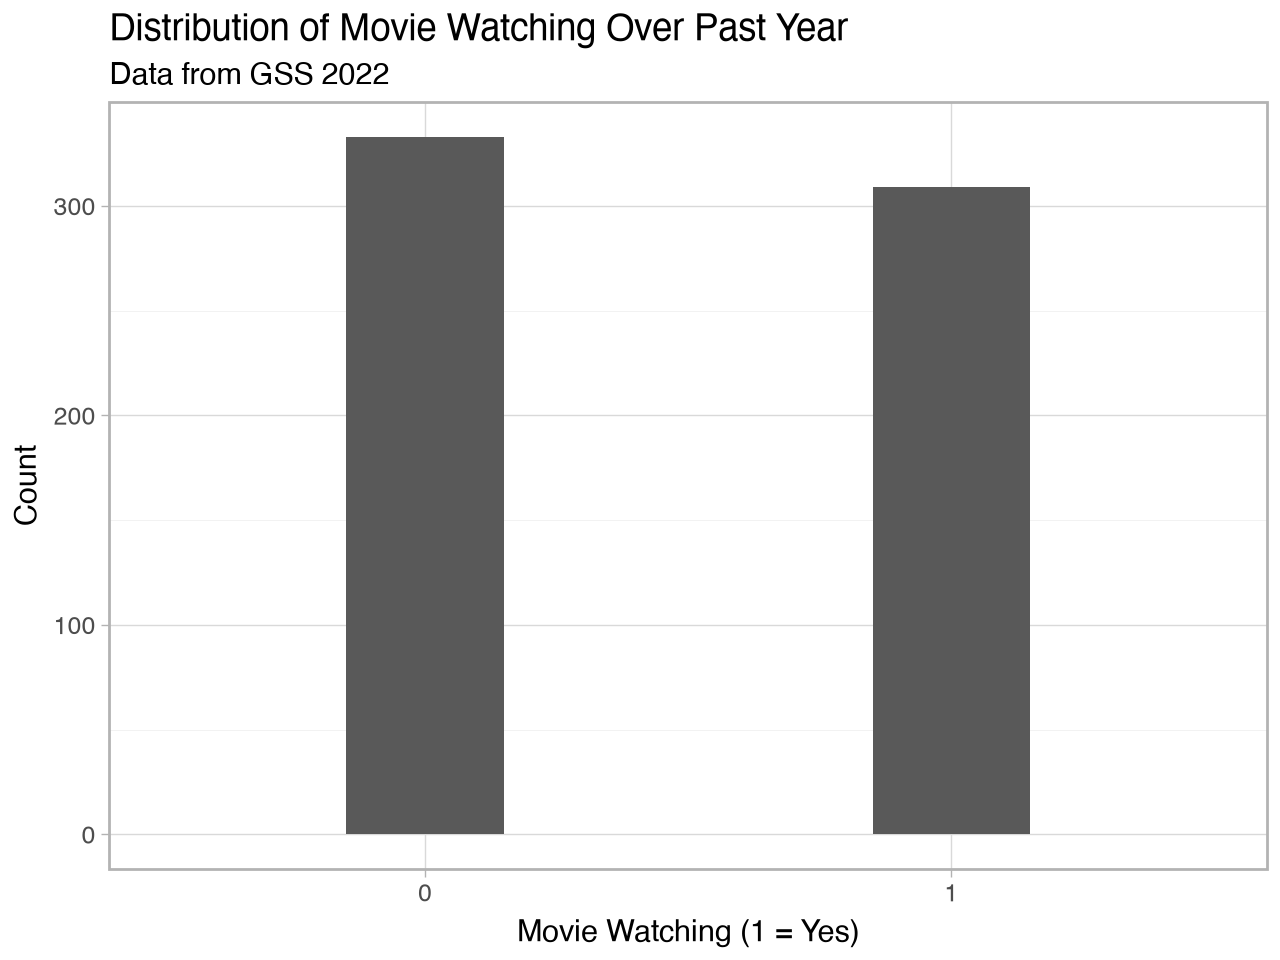

In [123]:
p = (
	p9.ggplot(df_large) +
	p9.geom_bar(p9.aes(x='factor(binary_movie)'), width=0.3) +
	p9.theme_light() +
	p9.labs(x='Movie Watching (1 = Yes)', y='Count',
			title='Distribution of Movie Watching Over Past Year',
			subtitle='Data from GSS 2022')
)
p.save('bar_movies.png', width=15, height=10.5, units='cm')
p

## Plot a histogram of the omnivorousness index

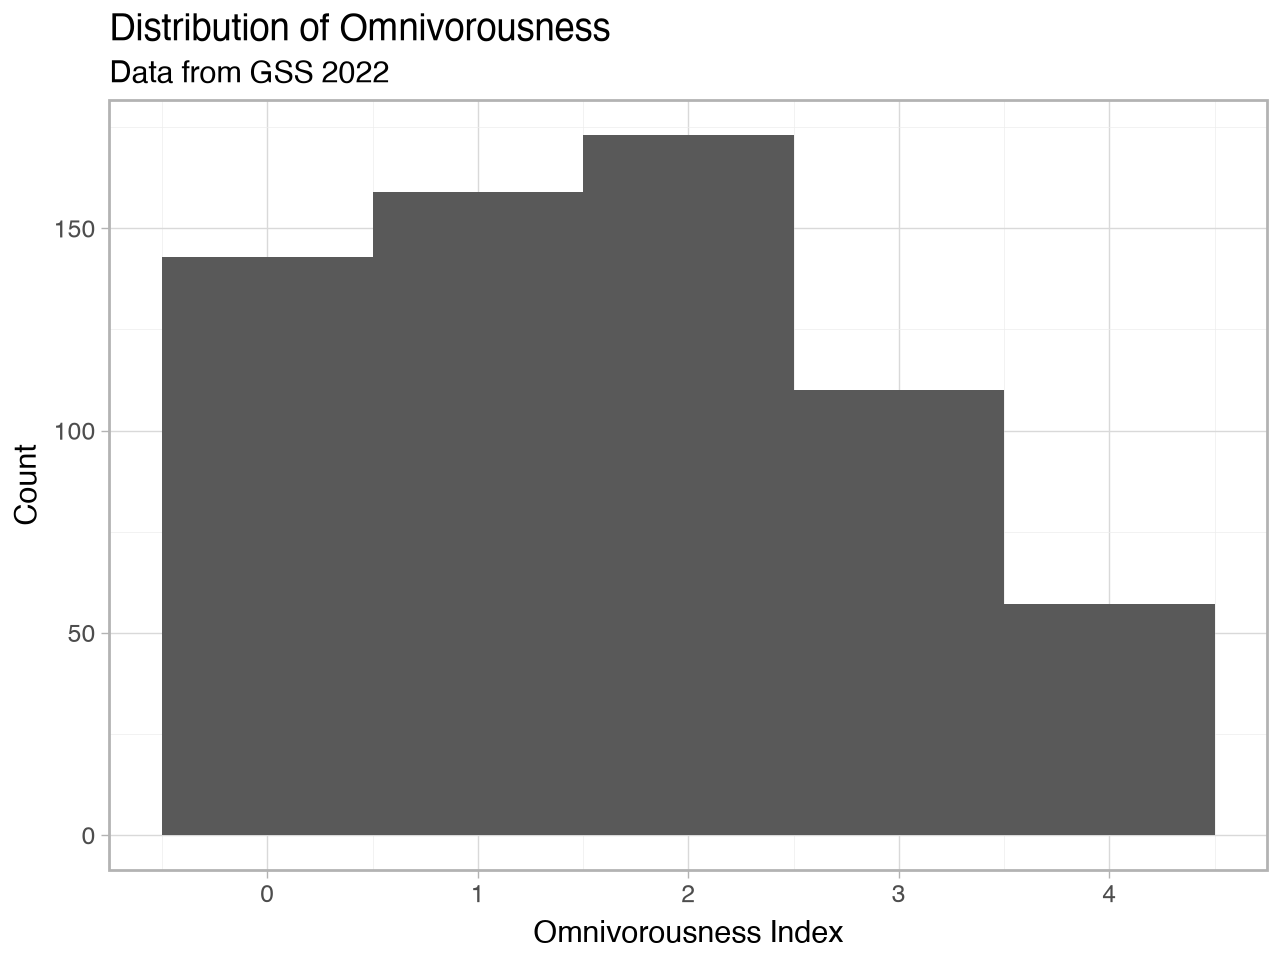

In [124]:
p = (
	p9.ggplot(df_large) +
	p9.geom_histogram(p9.aes(x='omni'), binwidth=1) + # you control the bin width, and thus the story being told as well
	p9.theme_light() +
	p9.labs(x='Omnivorousness Index', y='Count',
			title='Distribution of Omnivorousness',
			subtitle='Data from GSS 2022')
)
p.save('hist_omni.png', width=15, height=10.5, units='cm')
p

# Compare Distributions of Two Continuous Variables

We compare household income with occupational prestige using the large sample.

## Scale the variables

Standardize so both variables are on the same scale (mean = 0, SD = 1). Equivalent to R's `scale()`.

In [125]:
# z-score = (data point - mean) / standard deviation 
# tells us the number of standard deviations from the mean each data point is 
# helps us standardise as the variables income and prestige have different units -- this puts them on the same scale!

df_large = df_large.copy()
df_large['scaled_income'] = (df_large['income_cont'] - df_large['income_cont'].mean()) / df_large['income_cont'].std()
df_large['scaled_prestg'] = (df_large['prestg10'] - df_large['prestg10'].mean()) / df_large['prestg10'].std()
df_large['scaled_income']

4      -0.891461
17      1.757640
18     -1.274108
20     -0.538247
22     -0.655985
          ...   
3523    0.403656
3531    0.403656
3534    0.815738
3535   -0.538247
3537   -1.274108
Name: scaled_income, Length: 642, dtype: float64

## Plot the distributions of each variable

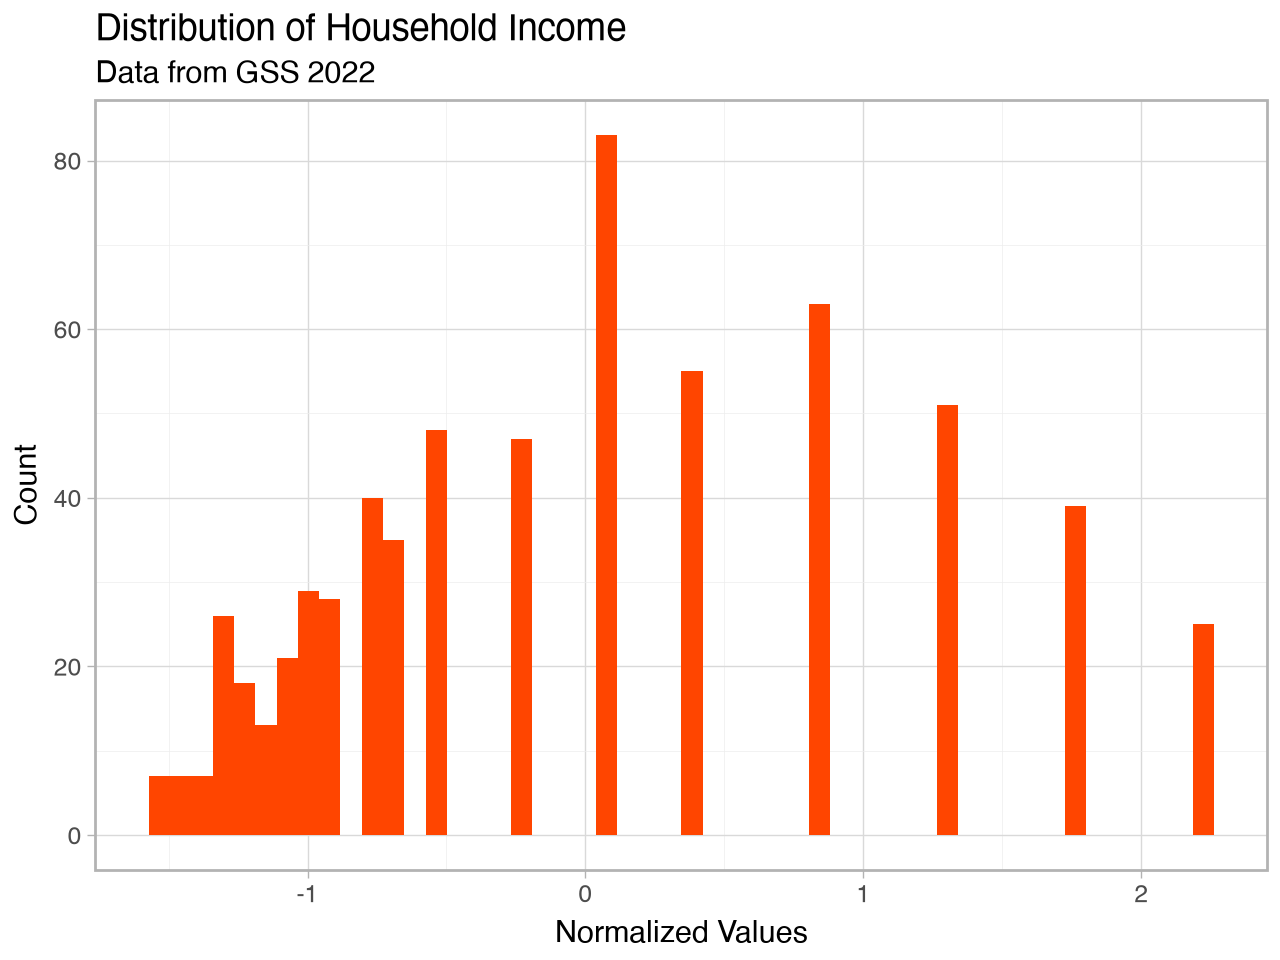

In [126]:
p = (
	p9.ggplot(df_large) +
	p9.geom_histogram(p9.aes(x='scaled_income'), bins=50, fill='orangered') +
	p9.theme_light() +
	p9.labs(x='Normalized Values', y='Count',
			title='Distribution of Household Income', subtitle='Data from GSS 2022')
)
p.save('hist_income.png', width=15, height=10.5, units='cm')
p

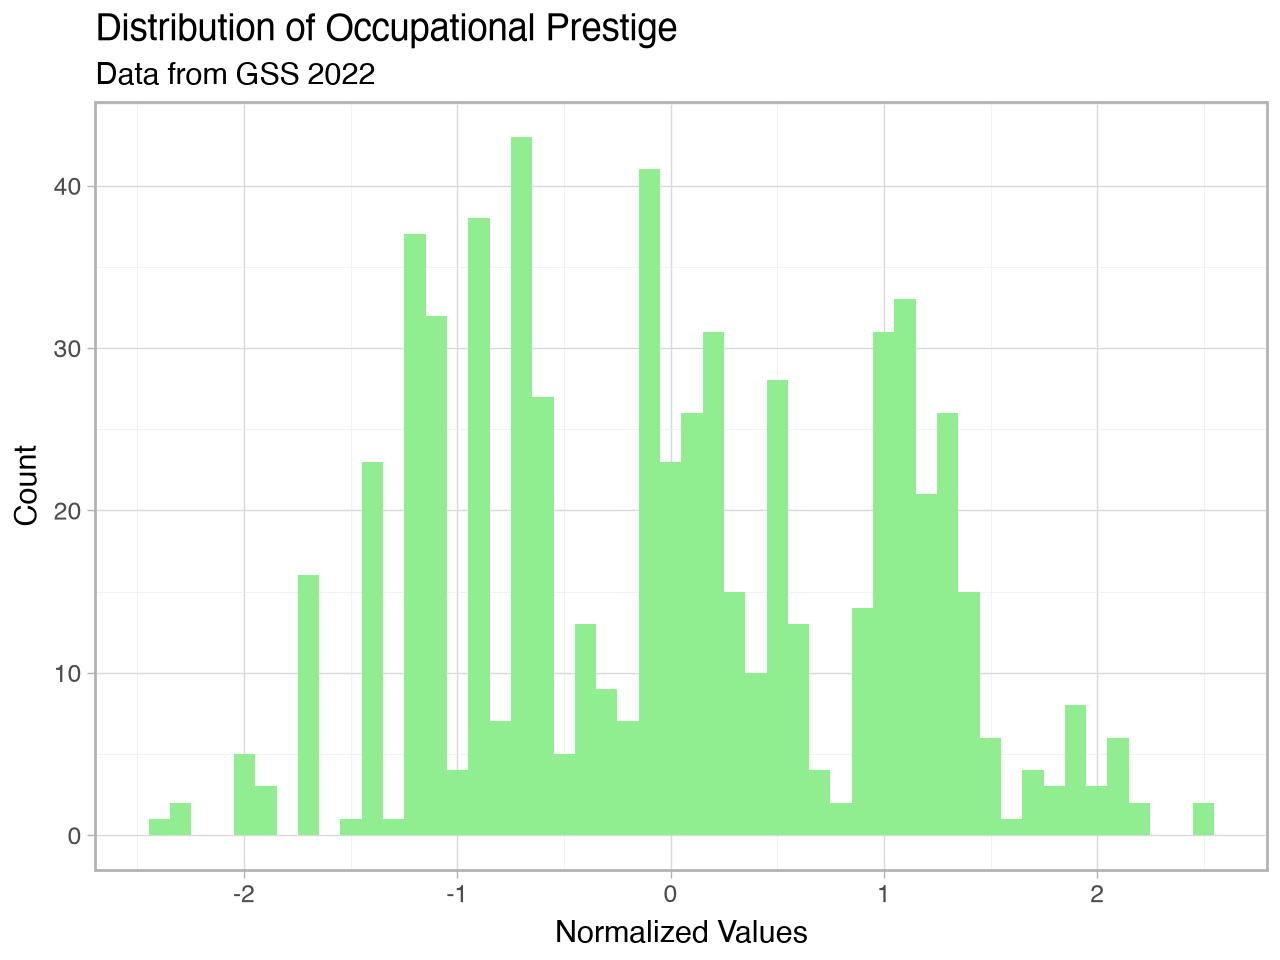

In [127]:
h = (p9.ggplot(df_large) + 
p9.geom_histogram(p9.aes(x='scaled_prestg'), bins = 50, fill='lightgreen') + 
p9.theme_light() + 
p9.labs(x='Normalized Values', y='Count', title='Distribution of Occupational Prestige', subtitle='Data from GSS 2022'))
p.save('hist_prestg.png', width=15, height=10.5, units='cm')
h

## Calculate Skewness of each variable

Skewness > 0 is right-skewed (long right tail); < 0 is left-skewed.

In [128]:
print('Skewness of Income (scaled):',  skew(df_large['scaled_income']))
# since skewness > 0, the distribution of income is positively skewed, with a longer right tail

Skewness of Income (scaled): 0.5518200686840499


## Calculate Kurtosis of each variable

`scipy.stats.kurtosis` with `fisher=False` gives Pearson kurtosis (same as R's `moments::kurtosis`). A normal distribution has kurtosis ≈ 3 (mesokurtic); > 3 is leptokurtic.

In [129]:
# fisher=False gives Pearson kurtosis — equivalent to R's moments::kurtosis()
print('Kurtosis of Income (scaled):',  kurtosis(df_large['scaled_income'], fisher=False))
# since kurtosis < 3, distribution is platykurtic. it has light tails, and thus there are few extreme values

Kurtosis of Income (scaled): 2.3174375995622825


In [130]:
!jupyter nbconvert --to pdf week3_notebook_student.ipynb

[NbConvertApp] Converting notebook week3_notebook_student.ipynb to pdf
[NbConvertApp] Support files will be in week3_notebook_student_files/
[NbConvertApp] Making directory ./week3_notebook_student_files
[NbConvertApp] Writing 51013 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 208034 bytes to week3_notebook_student.pdf
